In [2]:
# CELL 1 — IMPORT LIBRARY
# File: 05_image_ms_hc.ipynb
# Deskripsi: Pipeline klasifikasi MS/RIS vs Healthy Control
#            menggunakan CNN Feature Extractor (ResNet50) +
#            PCA + GB/XGBoost/MLP.
#            Dataset: 93 MS/RIS + 100 HC = 193 subjek
#            Label: MS/RIS=1, Healthy Control=0
# ============================================================

# --- Library standar ---
import os
import warnings
warnings.filterwarnings('ignore')

# --- Manipulasi data ---
import numpy as np
import pandas as pd

# --- Library khusus MRI ---
import nibabel as nib

# --- Image processing ---
from PIL import Image
import cv2

# --- Deep Learning: CNN Feature Extractor ---
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model

# --- Reduksi dimensi ---
from sklearn.decomposition import PCA

# --- Preprocessing & Split ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold,
                                     train_test_split)
# --- Evaluasi ---
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              roc_auc_score, confusion_matrix,
                              classification_report,
                              roc_curve, auc)

# --- Algoritma model ---
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

# --- Visualisasi ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# --- Utilities ---
from tqdm import tqdm
import joblib

# ── Konfigurasi tampilan ──────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 120

# ── Reproducibility ───────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ── Konfigurasi GPU ───────────────────────────────────────────
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"  GPU terdeteksi: {len(gpus)} unit")
    except RuntimeError as e:
        print(f"  GPU config error: {e}")
else:
    print("  Tidak ada GPU — berjalan di CPU")

# ── Verifikasi versi ──────────────────────────────────────────
print("=" * 60)
print("   VERIFIKASI LIBRARY — 05_image_ms_hc.ipynb")
print("=" * 60)
print(f"  numpy        : {np.__version__}")
print(f"  pandas       : {pd.__version__}")
print(f"  tensorflow   : {tf.__version__}")
print(f"  nibabel      : {nib.__version__}")
print(f"  PIL (Pillow) : {Image.__version__}")
import sklearn, xgboost, matplotlib
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  xgboost      : {xgboost.__version__}")
print(f"  matplotlib   : {matplotlib.__version__}")
print(f"  seaborn      : {sns.__version__}")
print("=" * 60)
print("  Semua library berhasil diimport!")
print("=" * 60)
print("  Lanjut ke Cell 2 — Eksplorasi Struktur Dataset")

  Tidak ada GPU — berjalan di CPU
   VERIFIKASI LIBRARY — 05_image_ms_hc.ipynb
  numpy        : 2.3.1
  pandas       : 2.3.1
  tensorflow   : 2.21.0
  nibabel      : 5.4.2
  PIL (Pillow) : 11.3.0
  scikit-learn : 1.7.1
  xgboost      : 3.0.1
  matplotlib   : 3.10.0
  seaborn      : 0.13.2
  Semua library berhasil diimport!
  Lanjut ke Cell 2 — Eksplorasi Struktur Dataset


In [4]:
# CELL 2 — EKSPLORASI STRUKTUR DATASET & BUILD MANIFEST
# Deskripsi: Scan folder MS/ dan Norm/, tangani variasi
#            session (multiple/non-001), validasi file .nii,
#            dan bangun df_manifest sebagai fondasi pipeline.
# ============================================================

# ── Konfigurasi path ─────────────────────────────────────────
BASE_PATH  = r"sibbms"       # ← sesuaikan jika perlu
PATH_MS    = os.path.join(BASE_PATH, "MS")
PATH_NORM  = os.path.join(BASE_PATH, "Norm")

# Sekuens yang digunakan — ce-GAD diabaikan karena tidak konsisten
SEQUENCES  = ['FLAIR', 'T1w', 'T2w']

# ── Section 1: Validasi Keberadaan Folder Root ───────────────
print("=" * 60)
print("Section 1: Validasi Folder Root")
print("=" * 60)

for label, path in [("Base", BASE_PATH),
                      ("MS",   PATH_MS),
                      ("Norm", PATH_NORM)]:
    status = "✓ ADA" if os.path.isdir(path) else "✗ TIDAK ADA"
    print(f"  {label:<6}: {status} — {path}")

# ── Section 2: Fungsi Helper Scan Subjek ─────────────────────
print("\nSection 2: Definisi Fungsi Helper")
print("-" * 60)

def get_baseline_session(sub_path):
    """
    Ambil session pertama yang tersedia (sorted alphabetical).
    Menangani: single session, multiple sessions,
               session tidak mulai dari ses-001.
    Return: (session_name, session_path) atau (None, None)
    """
    try:
        entries  = os.listdir(sub_path)
        sessions = sorted([
            e for e in entries
            if e.startswith('ses-') and
               os.path.isdir(os.path.join(sub_path, e))
        ])
        if not sessions:
            return None, None
        ses_name = sessions[0]          # ambil yang pertama (baseline)
        ses_path = os.path.join(sub_path, ses_name, 'anat')
        return ses_name, ses_path
    except:
        return None, None

def find_sequence_file(anat_path, sub_id, ses_id, seq_suffix):
    """
    Cari file .nii dengan pola sub-XXX_ses-XXX_{seq_suffix}.nii
    Return: full path jika ada, None jika tidak ada.
    """
    if not os.path.isdir(anat_path):
        return None
    target = f"{sub_id}_{ses_id}_{seq_suffix}.nii"
    fpath  = os.path.join(anat_path, target)
    return fpath if os.path.exists(fpath) else None

def scan_group(group_path, label, group_name):
    """
    Scan seluruh subjek dalam satu grup (MS atau Norm).
    Return: list of dict berisi info per subjek.
    """
    records = []
    try:
        subjects = sorted([
            s for s in os.listdir(group_path)
            if s.startswith('sub-') and
               os.path.isdir(os.path.join(group_path, s))
        ])
    except:
        return records

    for sub_id in subjects:
        sub_path  = os.path.join(group_path, sub_id)
        ses_id, anat_path = get_baseline_session(sub_path)

        if ses_id is None:
            records.append({
                'subject_id'  : sub_id,
                'group'       : group_name,
                'label'       : label,
                'session'     : None,
                'path_flair'  : None,
                'path_t1w'    : None,
                'path_t2w'    : None,
                'status'      : 'NO_SESSION'
            })
            continue

        # Cari setiap sekuens
        path_flair = find_sequence_file(
            anat_path, sub_id, ses_id, 'FLAIR')
        path_t1w   = find_sequence_file(
            anat_path, sub_id, ses_id, 'T1w')
        path_t2w   = find_sequence_file(
            anat_path, sub_id, ses_id, 'T2w')

        # Tentukan status kelengkapan
        missing = []
        if path_flair is None: missing.append('FLAIR')
        if path_t1w   is None: missing.append('T1w')
        if path_t2w   is None: missing.append('T2w')

        status = 'COMPLETE' if not missing \
                 else f'MISSING: {",".join(missing)}'

        records.append({
            'subject_id'  : sub_id,
            'group'       : group_name,
            'label'       : label,
            'session'     : ses_id,
            'path_flair'  : path_flair,
            'path_t1w'    : path_t1w,
            'path_t2w'    : path_t2w,
            'status'      : status
        })
    return records

print("  get_baseline_session() — ambil session pertama (sorted)")
print("  find_sequence_file()   — cari file .nii per sekuens")
print("  scan_group()           — scan seluruh subjek per grup")

# ── Section 3: Scan Kedua Grup ────────────────────────────────
print("\nSection 3: Scan Folder MS dan Norm")
print("-" * 60)

records_ms   = scan_group(PATH_MS,   label=1, group_name='MS')
records_norm = scan_group(PATH_NORM, label=0, group_name='HC')

df_manifest  = pd.DataFrame(records_ms + records_norm)

print(f"  Subjek MS ditemukan   : {len(records_ms)}")
print(f"  Subjek HC ditemukan   : {len(records_norm)}")
print(f"  Total df_manifest     : {len(df_manifest)} baris")

# ── Section 4: Audit Status Kelengkapan ──────────────────────
print("\nSection 4: Audit Status Kelengkapan File")
print("-" * 60)

status_counts = df_manifest.groupby(['group', 'status']).size()
print(status_counts.to_string())

# Pisahkan subjek complete vs incomplete
df_complete   = df_manifest[df_manifest['status'] == 'COMPLETE'].copy()
df_incomplete = df_manifest[df_manifest['status'] != 'COMPLETE'].copy()

print(f"\n  Subjek COMPLETE   : {len(df_complete)}")
print(f"  Subjek INCOMPLETE : {len(df_incomplete)}")

if len(df_incomplete) > 0:
    print(f"\n  Detail subjek tidak lengkap:")
    print(df_incomplete[['subject_id', 'group',
                          'status']].to_string(index=False))

# ── Section 5: Audit Variasi Session ─────────────────────────
print("\nSection 5: Audit Variasi Session")
print("-" * 60)

for grp in ['MS', 'HC']:
    sub_df   = df_manifest[df_manifest['group'] == grp]
    ses_vals = sub_df['session'].value_counts().sort_index()
    print(f"\n  [{grp}] Distribusi session yang dipilih:")
    print(ses_vals.to_string())

# Subjek dengan non-ses-001
non_ses001 = df_manifest[
    (df_manifest['session'].notna()) &
    (df_manifest['session'] != 'ses-001')
]
if len(non_ses001) > 0:
    print(f"\n  Subjek dengan session bukan ses-001 ({len(non_ses001)}):")
    print(non_ses001[['subject_id', 'group', 'session']]
          .to_string(index=False))
else:
    print("\n  Semua subjek menggunakan ses-001")

# ── Section 6: Distribusi Kelas Final ────────────────────────
print("\nSection 6: Distribusi Kelas (Subjek COMPLETE)")
print("-" * 60)

for lbl, name in [(1, 'MS/RIS'), (0, 'Healthy Control')]:
    cnt = sum(df_complete['label'] == lbl)
    pct = cnt / len(df_complete) * 100
    bar = '█' * int(pct / 2)
    print(f"  Label {lbl} ({name:<17}): {cnt:>3} ({pct:.1f}%) {bar}")

ir = (max(sum(df_complete['label']==1),
          sum(df_complete['label']==0)) /
      min(sum(df_complete['label']==1),
          sum(df_complete['label']==0)))
print(f"\n  Imbalance Ratio : {ir:.2f}:1")
if ir <= 1.5:
    print("  → IR ≤ 1.5 — distribusi seimbang, augmentasi tidak diperlukan")

# ── Section 7: Preview & Simpan Manifest ─────────────────────
print("\nSection 7: Preview df_manifest")
print("-" * 60)
display(df_complete[['subject_id', 'group', 'label',
                       'session', 'status']].head(6))

df_manifest.to_csv('ConfigdanOutputCNN189\manifest_193.csv', index=False)
print(f"  Manifest disimpan: 'ConfigdanOutputCNN189\manifest_193.csv'")

print("\n" + "=" * 60)
print("  Section 8 — Ringkasan")
print("=" * 60)
print(f"  Total subjek di-scan   : {len(df_manifest)}")
print(f"  Subjek COMPLETE        : {len(df_complete)}")
print(f"  Subjek INCOMPLETE      : {len(df_incomplete)}")
print(f"  Sekuens digunakan      : FLAIR, T1w, T2w")
print(f"  Label                  : MS/RIS=1, HC=0")
print("=" * 60)
print("  Variabel aktif: df_manifest, df_complete")
print("  Lanjut ke Cell 3 — Load Metadata Excel")

Section 1: Validasi Folder Root
  Base  : ✓ ADA — sibbms
  MS    : ✓ ADA — sibbms\MS
  Norm  : ✓ ADA — sibbms\Norm

Section 2: Definisi Fungsi Helper
------------------------------------------------------------
  get_baseline_session() — ambil session pertama (sorted)
  find_sequence_file()   — cari file .nii per sekuens
  scan_group()           — scan seluruh subjek per grup

Section 3: Scan Folder MS dan Norm
------------------------------------------------------------
  Subjek MS ditemukan   : 93
  Subjek HC ditemukan   : 100
  Total df_manifest     : 193 baris

Section 4: Audit Status Kelengkapan File
------------------------------------------------------------
group  status            
HC     COMPLETE              100
MS     COMPLETE               89
       MISSING: FLAIR          2
       MISSING: FLAIR,T2w      2

  Subjek COMPLETE   : 189
  Subjek INCOMPLETE : 4

  Detail subjek tidak lengkap:
subject_id group             status
   sub-003    MS     MISSING: FLAIR
   sub-006   

,subject_id,group,label,session,status
0,sub-001,MS,1,ses-001,COMPLETE
1,sub-002,MS,1,ses-001,COMPLETE
3,sub-004,MS,1,ses-001,COMPLETE
4,sub-005,MS,1,ses-001,COMPLETE
6,sub-007,MS,1,ses-001,COMPLETE
7,sub-008,MS,1,ses-001,COMPLETE


  Manifest disimpan: 'ConfigdanOutputCNN189\manifest_193.csv'

  Section 8 — Ringkasan
  Total subjek di-scan   : 193
  Subjek COMPLETE        : 189
  Subjek INCOMPLETE      : 4
  Sekuens digunakan      : FLAIR, T1w, T2w
  Label                  : MS/RIS=1, HC=0
  Variabel aktif: df_manifest, df_complete
  Lanjut ke Cell 3 — Load Metadata Excel


In [5]:
# CELL 3 — LOAD METADATA EXCEL
# Deskripsi: Load Cohort analysis_MS_data.xlsx sebagai
#            referensi deskriptif karakteristik pasien MS.
#            BUKAN sumber label — label dari struktur folder.
#            Output: df_meta_ms untuk analisis deskriptif.
# ============================================================

EXCEL_PATH = "sibbms\Cohort analysis_MS_data.xlsx"  # ← sesuaikan path

# ── Section 1: Validasi & Load File Excel ────────────────────
print("=" * 60)
print("Section 1: Validasi & Load File Excel")
print("=" * 60)

if not os.path.exists(EXCEL_PATH):
    print(f"  ✗ File tidak ditemukan: {EXCEL_PATH}")
    print("  → Sesuaikan EXCEL_PATH di atas")
else:
    print(f"  ✓ File ditemukan: {EXCEL_PATH}")

# Coba load — cek apakah perlu header=0 atau header=1
df_raw = pd.read_excel(EXCEL_PATH, header= 0)
print(f"\n  Shape awal   : {df_raw.shape}")
print(f"  Kolom awal   : {list(df_raw.columns)}")
print(f"\n  Preview 3 baris pertama:")
display(df_raw.head(3))

# ── Section 2: Normalisasi Kolom ─────────────────────────────
print("\nSection 2: Normalisasi Nama Kolom")
print("-" * 60)

df_meta_ms = df_raw.copy()
df_meta_ms.columns = (df_meta_ms.columns
                      .str.strip()
                      .str.lower()
                      .str.replace(' ', '_')
                      .str.replace('(', '')
                      .str.replace(')', ''))

print(f"  Kolom setelah normalisasi:")
for i, col in enumerate(df_meta_ms.columns, 1):
    print(f"    {i:>2}. {col}")

# ── Section 3: Statistik Deskriptif ──────────────────────────
print("\nSection 3: Statistik Deskriptif Kohort MS")
print("-" * 60)

# Identifikasi kolom kunci secara otomatis
cols_all    = df_meta_ms.columns.tolist()
col_age     = next((c for c in cols_all if 'age'     in c
                     and 'onset' not in c), None)
col_onset   = next((c for c in cols_all if 'onset'  in c), None)
col_dur     = next((c for c in cols_all if 'durat'  in c), None)
col_edss    = next((c for c in cols_all if 'edss'   in c), None)
col_subtype = next((c for c in cols_all if 'subtype'in c), None)
col_gender  = next((c for c in cols_all if 'gender' in c
                     or 'sex' in c), None)
col_dmt     = next((c for c in cols_all if 'therap' in c
                     or 'dmt'    in c
                     or 'modif'  in c), None)

print(f"  Kolom teridentifikasi otomatis:")
print(f"    Age          : '{col_age}'")
print(f"    Age of onset : '{col_onset}'")
print(f"    Duration     : '{col_dur}'")
print(f"    EDSS         : '{col_edss}'")
print(f"    Subtype      : '{col_subtype}'")
print(f"    Gender       : '{col_gender}'")
print(f"    DMT          : '{col_dmt}'")

# Statistik numerik
num_cols = [c for c in
            [col_age, col_onset, col_dur, col_edss]
            if c is not None]
if num_cols:
    print(f"\n  Statistik deskriptif (numerik):")
    display(df_meta_ms[num_cols].describe().round(2))

# Distribusi gender
if col_gender:
    print(f"\n  Distribusi Gender:")
    print(df_meta_ms[col_gender].value_counts().to_string())

# Distribusi disease subtype
if col_subtype:
    subtype_map = {0:'RRMS', 1:'SPMS', 2:'PPMS', 3:'RIS'}
    print(f"\n  Distribusi Disease Subtype:")
    subtype_counts = df_meta_ms[col_subtype].value_counts().sort_index()
    for code, cnt in subtype_counts.items():
        name = subtype_map.get(int(code), f'Kode-{code}')
        print(f"    {code} ({name:<5}): {cnt} pasien")

# ── Section 4: Sinkronisasi dengan df_complete ───────────────
print("\nSection 4: Sinkronisasi Excel dengan df_complete")
print("-" * 60)

# Subjek MS di df_complete → ekstrak nomor integer dari 'sub-001' → 1
ms_complete_ids = set(
    df_complete[df_complete['group'] == 'MS']['subject_id']
    .str.extract(r'sub-(\d+)')[0]
    .astype(int)
)

# Nomor baris Excel diasumsikan = nomor urut subjek (1-93)
# Karena Excel berisi 93 baris untuk 93 pasien MS
excel_ids = set(range(1, len(df_meta_ms) + 1))

excluded_ids = excel_ids - ms_complete_ids

print(f"  Subjek MS di df_complete  : {len(ms_complete_ids)}")
print(f"  Baris di Excel            : {len(df_meta_ms)}")
print(f"  Nomor subjek dieksklusi   : {sorted(excluded_ids)}")

if excluded_ids:
    print(f"\n  Detail subjek dieksklusi (baris Excel):")
    # Akses baris Excel berdasarkan index (0-based → -1)
    excl_rows = df_meta_ms.iloc[[i-1 for i in excluded_ids]]
    display(excl_rows)
else:
    print("Sinkronisasi sempurna")
  
# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan")
print("=" * 60)
print(f"  File Excel         : {EXCEL_PATH}")
print(f"  Total baris Excel  : {len(df_meta_ms)}")
print(f"  Fungsi             : Referensi deskriptif (BUKAN sumber label)")
print(f"  Sumber label       : Struktur folder MS/ vs Norm/")
print("\n  Kolom kunci untuk bab hasil skripsi:")
for k, v in {'Usia'       : col_age,
              'Age Onset'  : col_onset,
              'Duration'   : col_dur,
              'EDSS'       : col_edss,
              'Subtype'    : col_subtype,
              'Gender'     : col_gender,
              'DMT'        : col_dmt}.items():
    status = f"✓ '{v}'" if v else "✗ tidak terdeteksi"
    print(f"    {k:<12}: {status}")
print("=" * 60)
print("  Variabel aktif: df_meta_ms")
print("  Lanjut ke Cell 4 — CNN Feature Extraction (ResNet50)")

Section 1: Validasi & Load File Excel
  ✓ File ditemukan: sibbms\Cohort analysis_MS_data.xlsx

  Shape awal   : (93, 9)
  Kolom awal   : ['№', 'Anonymized ID', 'Age', 'Gender (0 - female, 1 - male)', 'Age of onset', ' Disease duration', 'Disease subtype (0 - RRMS, 1 - SPMS, 2 - PPMS, 3 - RIS)', 'Disease Modifying Therapy (0 - no, 1 - yes)', 'EDSS']

  Preview 3 baris pertama:


,№,Anonymized ID,Age,"Gender (0 - female, 1 - male)",Age of onset,Disease duration,"Disease subtype (0 - RRMS, 1 - SPMS, 2 - PPMS, 3 - RIS)","Disease Modifying Therapy (0 - no, 1 - yes)",EDSS
0,1,sub-001,23,0,20,3,3,0,1
1,2,sub-002,41,0,38,3,0,1,2025-05-01 00:00:00
2,3,sub-003,47,1,45,3,1,0,2025-05-06 00:00:00



Section 2: Normalisasi Nama Kolom
------------------------------------------------------------
  Kolom setelah normalisasi:
     1. №
     2. anonymized_id
     3. age
     4. gender_0_-_female,_1_-_male
     5. age_of_onset
     6. disease_duration
     7. disease_subtype_0_-_rrms,_1_-_spms,_2_-_ppms,_3_-_ris
     8. disease_modifying_therapy_0_-_no,_1_-_yes
     9. edss

Section 3: Statistik Deskriptif Kohort MS
------------------------------------------------------------
  Kolom teridentifikasi otomatis:
    Age          : 'age'
    Age of onset : 'age_of_onset'
    Duration     : 'disease_duration'
    EDSS         : 'edss'
    Subtype      : 'disease_subtype_0_-_rrms,_1_-_spms,_2_-_ppms,_3_-_ris'
    Gender       : 'gender_0_-_female,_1_-_male'
    DMT          : 'disease_modifying_therapy_0_-_no,_1_-_yes'

  Statistik deskriptif (numerik):


,age,age_of_onset,disease_duration
count,93.0000,93.0000,93.0000
mean,41.0600,32.1200,9.2800
std,11.4200,11.3500,6.4200
min,19.0000,10.0000,0.0000
25%,33.0000,24.0000,5.0000
50%,39.0000,31.0000,8.0000
75%,47.0000,39.0000,13.0000
max,71.0000,66.0000,46.0000



  Distribusi Gender:
gender_0_-_female,_1_-_male
0    57
1    36

  Distribusi Disease Subtype:
    0 (RRMS ): 57 pasien
    1 (SPMS ): 24 pasien
    2 (PPMS ): 5 pasien
    3 (RIS  ): 7 pasien

Section 4: Sinkronisasi Excel dengan df_complete
------------------------------------------------------------
  Subjek MS di df_complete  : 89
  Baris di Excel            : 93
  Nomor subjek dieksklusi   : [3, 6, 57, 91]

  Detail subjek dieksklusi (baris Excel):


,№,anonymized_id,age,"gender_0_-_female,_1_-_male",age_of_onset,disease_duration,"disease_subtype_0_-_rrms,_1_-_spms,_2_-_ppms,_3_-_ris","disease_modifying_therapy_0_-_no,_1_-_yes",edss
56,57,sub-057,43,0,31,12,1,1,2025-05-06 00:00:00
90,91,sub-091,39,1,27,13,0,1,2
2,3,sub-003,47,1,45,3,1,0,2025-05-06 00:00:00
5,6,sub-006,44,1,44,1,2,1,2



  Section 5 — Ringkasan
  File Excel         : sibbms\Cohort analysis_MS_data.xlsx
  Total baris Excel  : 93
  Fungsi             : Referensi deskriptif (BUKAN sumber label)
  Sumber label       : Struktur folder MS/ vs Norm/

  Kolom kunci untuk bab hasil skripsi:
    Usia        : ✓ 'age'
    Age Onset   : ✓ 'age_of_onset'
    Duration    : ✓ 'disease_duration'
    EDSS        : ✓ 'edss'
    Subtype     : ✓ 'disease_subtype_0_-_rrms,_1_-_spms,_2_-_ppms,_3_-_ris'
    Gender      : ✓ 'gender_0_-_female,_1_-_male'
    DMT         : ✓ 'disease_modifying_therapy_0_-_no,_1_-_yes'
  Variabel aktif: df_meta_ms
  Lanjut ke Cell 4 — CNN Feature Extraction (ResNet50)


In [6]:
# CELL 4 — CNN FEATURE EXTRACTION (ResNet50)
# Deskripsi: Ekstraksi fitur dari 3 sekuens MRI per subjek
#            (FLAIR, T1w, T2w) menggunakan ResNet50 pretrained
#            (ImageNet, frozen). Path dari df_complete Cell 2.
#            Output: df_raw_features (189 × 6144) + cache CSV.
# ============================================================

# ── Konfigurasi ──────────────────────────────────────────────
CACHE_PATH  = "ConfigdanOutputCNN189\cnn_features_resnet50_189.csv"
N_SLICES    = 5       # slice tengah per sekuens
IMG_SIZE    = (224, 224)

# ── Section 1: Bangun ResNet50 Feature Extractor ─────────────
print("=" * 60)
print("Section 1: Inisialisasi ResNet50 Feature Extractor")
print("=" * 60)

base_model = ResNet50(
    weights     = 'imagenet',
    include_top = False,
    pooling     = 'avg',
    input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)
)
base_model.trainable = False

print(f"  Model      : ResNet50 (imagenet weights, frozen)")
print(f"  Input      : {IMG_SIZE} × 3 channel (pseudo-RGB)")
print(f"  Output     : (2048,) per sekuens via Global Avg Pooling")
print(f"  Total params: {base_model.count_params():,}")

# ── Section 2: Fungsi Helper ──────────────────────────────────
print("\nSection 2: Definisi Fungsi Helper")
print("-" * 60)

def load_nii_volume(path):
    """Load volume 3D dari .nii → numpy float32."""
    img  = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    if data.ndim == 4:
        data = data[..., 0]
    return data

def normalize_slice(slice_2d):
    """Normalisasi intensitas MRI → pseudo-RGB uint8."""
    mn, mx = slice_2d.min(), slice_2d.max()
    if mx - mn < 1e-8:
        return np.zeros((*slice_2d.shape, 3), dtype=np.uint8)
    norm = (slice_2d - mn) / (mx - mn) * 255.0
    u8   = norm.astype(np.uint8)
    return np.stack([u8] * 3, axis=-1)

def extract_features_from_volume(volume, n_slices=N_SLICES):
    """
    Ambil n_slices axial slice tengah → resize → ResNet50
    → average pooling → vektor (2048,).
    """
    depth      = volume.shape[2]
    mid        = depth // 2
    half       = n_slices // 2
    slice_idxs = range(max(0, mid-half), min(depth, mid+half+1))

    feats = []
    for idx in slice_idxs:
        s   = volume[:, :, idx]
        rgb = normalize_slice(s)
        pil = Image.fromarray(rgb).resize(IMG_SIZE, Image.BILINEAR)
        arr = np.array(pil, dtype=np.float32)
        arr = preprocess_input(arr[np.newaxis, ...])
        f   = base_model.predict(arr, verbose=0)
        feats.append(f[0])
    return np.mean(feats, axis=0)

def extract_subject_features(row):
    """
    Ekstraksi fitur satu subjek dari 3 sekuens.
    Input : baris df_complete (berisi path_flair, path_t1w, path_t2w)
    Output: np.array (6144,) atau None jika gagal
    """
    paths = {
        'flair': row['path_flair'],
        't1w'  : row['path_t1w'],
        't2w'  : row['path_t2w']
    }
    seq_vectors = []
    for seq_name, fpath in paths.items():
        if fpath is None:
            return None
        volume = load_nii_volume(fpath)
        feat   = extract_features_from_volume(volume)
        seq_vectors.append(feat)
    return np.concatenate(seq_vectors)   # (6144,)

print("  load_nii_volume()          — load file .nii")
print("  normalize_slice()          — normalisasi intensitas MRI")
print("  extract_features_from_volume() — ResNet50 + avg pooling")
print("  extract_subject_features() — pipeline per subjek (3 sekuens)")

# ── Section 3: Ekstraksi Fitur (dengan cache check) ──────────
print("\nSection 3: CNN Feature Extraction")
print("-" * 60)

if os.path.exists(CACHE_PATH):
    print(f"  ✓ Cache ditemukan: '{CACHE_PATH}'")
    print(f"  → Load dari cache (skip ekstraksi ulang)")
    df_raw_features = pd.read_csv(CACHE_PATH, index_col='subject_id')
    print(f"  Shape dari cache: {df_raw_features.shape}")

else:
    print(f"  Cache belum ada — mulai ekstraksi ResNet50...")
    print(f"  Total subjek  : {len(df_complete)}")
    print(f"  Sekuens/subjek: 3 (FLAIR, T1w, T2w)")
    print(f"  Slice/sekuens : {N_SLICES} slice tengah")
    print(f"  Estimasi CPU  : ~45–90 menit\n")

    all_features = {}
    failed       = []

    for _, row in tqdm(df_complete.iterrows(),
                        total=len(df_complete),
                        desc="Ekstraksi subjek",
                        unit="subj"):
        sub_id = row['subject_id']
        group   = row['group']
        
        # ── KUNCI FIX: buat unique_id dengan prefix group ─────────
        # MS sub-001 → 'MS_sub-001' | HC sub-001 → 'HC_sub-001'
        unique_id = f"{group}_{sub_id}"
        
        try:
            feat = extract_subject_features(row)
            if feat is not None:
                all_features[unique_id] = feat
            else:
                failed.append((unique_id, 'None path'))
        except Exception as e:
            failed.append((unique_id, str(e)))

    # Buat DataFrame — kolom: flair_0..2047, t1w_0..2047, t2w_0..2047
    feature_cols = (
        [f"flair_{i}" for i in range(2048)] +
        [f"t1w_{i}"   for i in range(2048)] +
        [f"t2w_{i}"   for i in range(2048)]
    )
    df_raw_features = pd.DataFrame.from_dict(
        all_features, orient='index', columns=feature_cols)
    df_raw_features.index.name = 'subject_id'

    # Simpan cache
    df_raw_features.to_csv(CACHE_PATH)
    print(f"\n  ✓ Ekstraksi selesai!")
    print(f"  Shape: {df_raw_features.shape}")
    print(f"  Cache disimpan: '{CACHE_PATH}'")

    if failed:
        print(f"\n  ⚠ Subjek gagal ({len(failed)}):")
        for sid, err in failed:
            print(f"    {sid}: {err[:60]}")

# ── Section 4: Sinkronisasi Label dari df_complete ───────────
print("\nSection 4: Sinkronisasi Label")
print("-" * 60)

# Bangun label_map dengan unique_id yang sama
df_complete_copy = df_complete.copy()
df_complete_copy['unique_id'] = (df_complete_copy['group']
                                  + '_'
                                  + df_complete_copy['subject_id'])

label_map  = df_complete_copy.set_index('unique_id')['label']
common_ids = df_raw_features.index.intersection(label_map.index)
df_raw_features = df_raw_features.loc[common_ids]
labels_series   = label_map.loc[common_ids]

print(f"  Subjek di df_raw_features : {len(df_raw_features)}")
print(f"  Label tersinkronisasi     : {len(labels_series)}")
print(f"  MS/RIS  (label=1)         : {sum(labels_series==1)}")
print(f"  HC      (label=0)         : {sum(labels_series==0)}")

# ── Section 5: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan Ekstraksi CNN")
print("=" * 60)
print(f"  Shape df_raw_features : {df_raw_features.shape}")
print(f"  → {df_raw_features.shape[0]} subjek × {df_raw_features.shape[1]} fitur")
print(f"  Breakdown fitur:")
print(f"    FLAIR : 2048 dimensi (indeks 0–2047)")
print(f"    T1w   : 2048 dimensi (indeks 2048–4095)")
print(f"    T2w   : 2048 dimensi (indeks 4096–6143)")
print(f"  Missing values        : {df_raw_features.isnull().sum().sum()}")
print(f"  Rentang nilai         : [{df_raw_features.values.min():.4f}, "
      f"{df_raw_features.values.max():.4f}]")
print("=" * 60)
print("  Variabel aktif: df_raw_features, labels_series")
print("  Lanjut ke Cell 5 — PCA Reduksi Dimensi")

Section 1: Inisialisasi ResNet50 Feature Extractor
  Model      : ResNet50 (imagenet weights, frozen)
  Input      : (224, 224) × 3 channel (pseudo-RGB)
  Output     : (2048,) per sekuens via Global Avg Pooling
  Total params: 23,587,712

Section 2: Definisi Fungsi Helper
------------------------------------------------------------
  load_nii_volume()          — load file .nii
  normalize_slice()          — normalisasi intensitas MRI
  extract_features_from_volume() — ResNet50 + avg pooling
  extract_subject_features() — pipeline per subjek (3 sekuens)

Section 3: CNN Feature Extraction
------------------------------------------------------------
  ✓ Cache ditemukan: 'ConfigdanOutputCNN189\cnn_features_resnet50_189.csv'
  → Load dari cache (skip ekstraksi ulang)
  Shape dari cache: (189, 6144)

Section 4: Sinkronisasi Label
------------------------------------------------------------
  Subjek di df_raw_features : 189
  Label tersinkronisasi     : 189
  MS/RIS  (label=1)         : 89
  

In [7]:
# Cek preview unique_id yang akan dibuat
preview = df_complete.apply(
    lambda r: f"{r['group']}_{r['subject_id']}", axis=1)
print("Sample unique_id:")
print(preview.head(5).tolist())
print(preview.tail(5).tolist())
print(f"\nTotal unik: {preview.nunique()} dari {len(preview)} baris")

Sample unique_id:
['MS_sub-001', 'MS_sub-002', 'MS_sub-004', 'MS_sub-005', 'MS_sub-007']
['HC_sub-096', 'HC_sub-097', 'HC_sub-098', 'HC_sub-099', 'HC_sub-100']

Total unik: 189 dari 189 baris


Section 1: Standarisasi Fitur Sebelum PCA
  Input shape     : (189, 6144)
  Setelah scaling : mean≈0, std≈1 per fitur
  Shape X_scaled  : (189, 6144)

Section 2: Fit PCA & Tentukan n_components Optimal
------------------------------------------------------------
  Total komponen maksimum : 189
  Threshold variance      : 95%
  n_components optimal    : 121
  Variance tercakup       : 95.01%
  Reduksi dimensi         : 6144 → 121 (98.0% dikurangi)

  Top-10 komponen PCA:
  PC      Var Ratio   Cumulative
  ------------------------------
  PC1       0.1761      0.1761
  PC2       0.0501      0.2261
  PC3       0.0435      0.2696
  PC4       0.0386      0.3082
  PC5       0.0345      0.3427
  PC6       0.0288      0.3716
  PC7       0.0240      0.3956
  PC8       0.0223      0.4179
  PC9       0.0202      0.4380
  PC10      0.0189      0.4569

Section 3: Scree Plot
------------------------------------------------------------


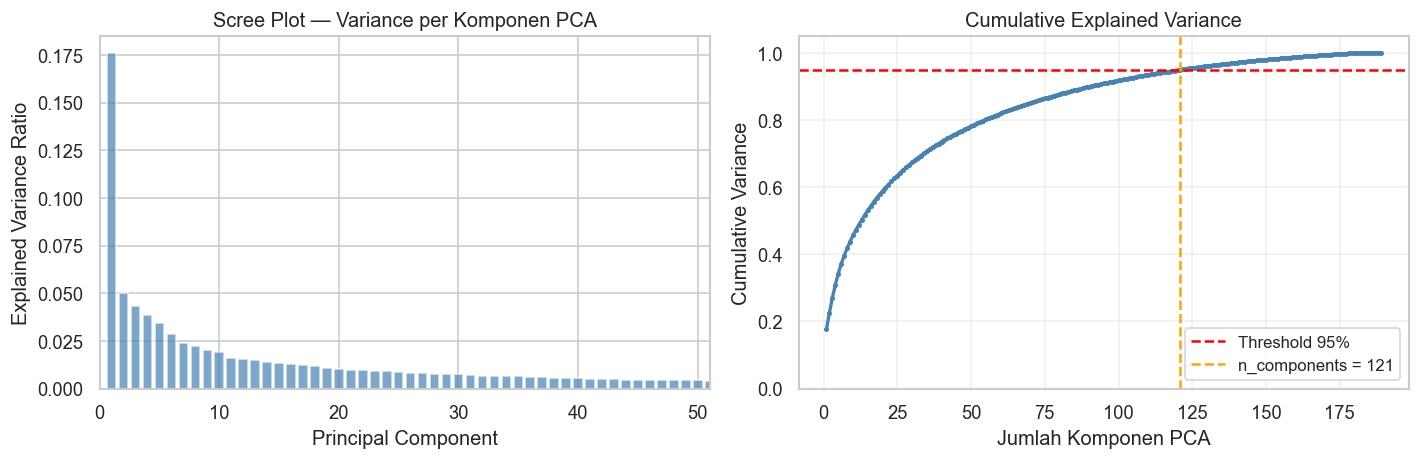

Plot disimpan: 'ConfigdanOutputCNN189\pca_scree_plot_189.png'

Section 4: Transform Data ke Ruang PCA Optimal
------------------------------------------------------------
  Shape df_cnn_features : (189, 121)
  Kolom                 : PC1 s/d PC121
  Variance tercakup     : 94.95%

  Preview (3 baris pertama):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37,PC38,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48,PC49,PC50,PC51,PC52,PC53,PC54,PC55,PC56,PC57,PC58,PC59,PC60,PC61,PC62,PC63,PC64,PC65,PC66,PC67,PC68,PC69,PC70,PC71,PC72,PC73,PC74,PC75,PC76,PC77,PC78,PC79,PC80,PC81,PC82,PC83,PC84,PC85,PC86,PC87,PC88,PC89,PC90,PC91,PC92,PC93,PC94,PC95,PC96,PC97,PC98,PC99,PC100,PC101,PC102,PC103,PC104,PC105,PC106,PC107,PC108,PC109,PC110,PC111,PC112,PC113,PC114,PC115,PC116,PC117,PC118,PC119,PC120,PC121
MS_sub-001,-16.0369,-14.4693,-17.6415,-17.2885,-33.0806,13.6581,6.4728,8.7365,-2.8702,-14.1448,17.7907,-0.7102,19.8567,14.3031,12.2496,6.2604,1.4085,4.0627,11.3819,5.6541,-7.0483,-8.4982,-0.9305,-2.0322,5.9397,-7.3150,3.6762,-6.5505,4.0368,-4.7662,-3.5850,-8.2691,-2.8843,-2.9711,-9.7462,-0.8566,1.7759,9.4877,-7.4800,10.5604,-3.2634,5.8129,-3.5036,-0.1600,-5.3481,-4.3709,6.0638,9.2781,10.8647,-2.9304,-5.3170,-0.9822,11.1990,-5.6812,-0.4339,-7.4097,-3.2819,7.3845,-2.8478,-7.5894,2.5492,-0.1603,2.7474,-6.0697,0.9582,-2.9555,2.2129,1.0361,0.3152,-7.4096,-5.2587,9.0603,-1.1406,-5.8906,-9.0217,-3.1663,1.6946,6.6948,4.4032,3.6252,-4.2747,-0.7810,2.0123,-2.3975,7.8989,-6.8969,-2.6282,0.4791,0.7208,1.3000,-7.4996,-1.7809,11.4504,1.0562,-8.4746,3.1924,-3.2891,1.3485,-2.9633,9.5492,-7.2125,-0.8653,0.1481,-0.8463,5.1736,-0.5630,5.3475,-3.9764,-3.7200,-3.9369,-5.9412,2.6648,2.5519,0.6923,-1.1033,-2.2481,-0.4656,-0.4914,2.8538,4.6767,-4.5963
MS_sub-002,-18.3155,3.3525,4.0741,7.0196,21.6774,1.4503,-9.9944,-7.9260,0.0950,0.8808,3.4647,2.4693,1.8290,6.4176,-9.0876,1.3944,2.8650,-9.5927,2.9425,0.2718,-6.0315,-0.2653,-0.5059,6.1895,-0.8124,-2.2462,1.4881,-1.4676,1.5936,1.7927,-5.3552,-2.3634,-0.3951,-3.0635,1.1588,-4.1244,5.4642,-3.4072,-0.8366,-0.8556,-0.5647,-5.4425,-2.7612,0.6961,0.3899,1.0402,1.6197,-2.6612,-0.0185,-0.0539,-2.4348,-2.4437,0.1881,-2.7665,1.8023,1.0483,-6.3784,-2.1840,1.5565,-2.3698,0.4843,0.0587,5.3644,0.9598,-2.1203,-1.4105,0.8002,-0.9553,-0.9354,3.5762,-0.3773,1.7933,4.2998,0.0366,-0.2783,2.0397,-1.6962,0.5166,1.6996,1.3017,-1.0707,-2.3075,-0.2428,3.6669,0.3499,-1.0171,-2.6724,0.1583,-0.2546,-0.8066,-0.8832,-1.9352,-2.4747,1.5165,-0.0047,-0.1690,-0.8388,-1.9143,2.9920,-1.1147,-0.3462,2.9245,2.3881,-0.4000,-2.1379,1.7807,-0.5202,0.2137,-2.1217,1.6337,-0.2726,-1.8703,-1.1620,-1.7051,-2.3793,1.7560,1.3039,-0.4598,0.9001,1.8859,-4.0145
MS_sub-004,-12.3854,-3.7647,-5.5752,6.7867,12.0095,-2.5265,23.0346,17.2247,-5.8632,6.1982,8.5302,1.4816,-6.3452,-10.9879,9.6881,-4.8939,-7.7920,0.8191,-3.4109,3.5080,3.3737,0.9463,1.9215,-1.7276,2.0059,-1.4170,1.4792,-0.4470,-1.7468,3.6789,2.0446,-5.0912,-3.6346,-3.6358,2.6879,0.7005,-2.0027,1.2284,-0.2945,-0.1289,-1.7147,-4.9375,-8.1942,0.9248,2.0295,2.9518,2.4982,0.5488,0.8344,-1.4562,-3.4129,-3.1025,0.2599,-0.1646,3.8533,2.5988,-5.7011,-0.7707,1.3975,-2.9584,1.0958,4.8973,-1.8778,-2.9255,0.3411,0.3937,-1.8156,-7.1100,0.0063,3.7478,4.3738,-0.6433,3.7206,-1.1632,-1.2866,6.1248,2.5390,7.2071,0.9483,2.9574,0.4962,-1.6459,1.1413,-1.3486,2.5971,-1.4011,4.9025,1.6732,-0.3359,4.6345,-2.6410,-0.6467,-2.7531,2.6242,2.4571,3.8577,1.1639,-1.7281,4.9675,-2.2450,1.6692,3.3321,-2.1471,1.5621,1.4493,6.2767,-6.3538,-1.6585,-6.4645,3.6899,1.2313,4.2284,-2.9832,1.9339,2.3925,-4.2018,4.7427,-1.0045,1.7547,1.3463,-5.6508



  Cache PCA disimpan: 'ConfigdanOutputCNN189\cnn_features_pca_189.csv'

  Section 5 — Ringkasan & Perbandingan
  Aspek                           Eks.1 (60 subj) Eks.3 (189 subj)
  ----------------------------------------------------------------
  Fitur CNN raw                             6,144            6,144
  n_components PCA                             47              121
  Variance tercakup                        95.48% 94.95%:>16
  Rasio sampel:fitur                   60:47=1.3x     189:121=1.6x
  Variabel aktif: df_cnn_features, pca_final, scaler_pca
                  labels_series (dari Cell 4)
  Lanjut ke Cell 6 — Labeling & Distribusi Kelas


In [9]:
# CELL 5 — PCA REDUKSI DIMENSI
# Deskripsi: Reduksi 6144 fitur CNN menjadi n_components
#            optimal (threshold explained_variance ≥ 95%).
#            Input : df_raw_features (189 × 6144)
#            Output: df_cnn_features (189 × n_pca) + cache CSV
# ============================================================

PCA_VARIANCE_THRESHOLD = 0.95
PCA_CACHE_PATH         = "ConfigdanOutputCNN189\cnn_features_pca_189.csv"

# ── Section 1: Standarisasi Sebelum PCA ──────────────────────
print("=" * 60)
print("Section 1: Standarisasi Fitur Sebelum PCA")
print("=" * 60)

scaler_pca = StandardScaler()
X_scaled   = scaler_pca.fit_transform(df_raw_features.values)

print(f"  Input shape     : {df_raw_features.shape}")
print(f"  Setelah scaling : mean≈0, std≈1 per fitur")
print(f"  Shape X_scaled  : {X_scaled.shape}")

# ── Section 2: Fit PCA & Tentukan n_components Optimal ───────
print("\nSection 2: Fit PCA & Tentukan n_components Optimal")
print("-" * 60)

# n_components = None → dibatasi min(n_samples, n_features)
# = min(189, 6144) = 189 komponen maksimum
pca_full = PCA(n_components=None, random_state=42)
pca_full.fit(X_scaled)

cumvar             = np.cumsum(pca_full.explained_variance_ratio_)
n_components_optimal = np.argmax(cumvar >= PCA_VARIANCE_THRESHOLD) + 1

print(f"  Total komponen maksimum : {len(cumvar)}")
print(f"  Threshold variance      : {PCA_VARIANCE_THRESHOLD*100:.0f}%")
print(f"  n_components optimal    : {n_components_optimal}")
print(f"  Variance tercakup       : {cumvar[n_components_optimal-1]*100:.2f}%")
print(f"  Reduksi dimensi         : 6144 → {n_components_optimal} "
      f"({(1-n_components_optimal/6144)*100:.1f}% dikurangi)")

print(f"\n  Top-10 komponen PCA:")
print(f"  {'PC':<6} {'Var Ratio':>10} {'Cumulative':>12}")
print(f"  {'-'*30}")
for i in range(min(10, len(cumvar))):
    print(f"  PC{i+1:<4} {pca_full.explained_variance_ratio_[i]:>9.4f}"
          f"  {cumvar[i]:>10.4f}")

# ── Section 3: Scree Plot ─────────────────────────────────────
print("\nSection 3: Scree Plot")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, len(cumvar)+1),
            pca_full.explained_variance_ratio_,
            color='steelblue', alpha=0.7, edgecolor='white')
axes[0].set_title('Scree Plot — Variance per Komponen PCA', fontsize=12)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_xlim([0, min(50, len(cumvar))+1])   # tampilkan 50 PC pertama

axes[1].plot(range(1, len(cumvar)+1), cumvar,
             marker='o', markersize=2,
             color='steelblue', linewidth=2)
axes[1].axhline(y=PCA_VARIANCE_THRESHOLD, color='red',
                linestyle='--', linewidth=1.5,
                label=f'Threshold {PCA_VARIANCE_THRESHOLD*100:.0f}%')
axes[1].axvline(x=n_components_optimal, color='orange',
                linestyle='--', linewidth=1.5,
                label=f'n_components = {n_components_optimal}')
axes[1].set_title('Cumulative Explained Variance', fontsize=12)
axes[1].set_xlabel('Jumlah Komponen PCA')
axes[1].set_ylabel('Cumulative Variance')
axes[1].set_ylim([0, 1.05])
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN189\pca_scree_plot_189.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot disimpan: 'ConfigdanOutputCNN189\pca_scree_plot_189.png'")

# ── Section 4: Transform ke Ruang PCA Optimal ────────────────
print("\nSection 4: Transform Data ke Ruang PCA Optimal")
print("-" * 60)

pca_final = PCA(n_components=n_components_optimal, random_state=42)
X_pca     = pca_final.fit_transform(X_scaled)

pca_cols        = [f"PC{i+1}" for i in range(n_components_optimal)]
df_cnn_features = pd.DataFrame(
    X_pca,
    index   = df_raw_features.index,
    columns = pca_cols
)

print(f"  Shape df_cnn_features : {df_cnn_features.shape}")
print(f"  Kolom                 : PC1 s/d PC{n_components_optimal}")
print(f"  Variance tercakup     : {pca_final.explained_variance_ratio_.sum()*100:.2f}%")
print(f"\n  Preview (3 baris pertama):")
display(df_cnn_features.head(3))

df_cnn_features.to_csv(PCA_CACHE_PATH)
print(f"\n  Cache PCA disimpan: '{PCA_CACHE_PATH}'")

# ── Section 5: Ringkasan & Justifikasi ───────────────────────
print("\n" + "=" * 60)
print("  Section 5 — Ringkasan & Perbandingan")
print("=" * 60)
print(f"  {'Aspek':<30} {'Eks.1 (60 subj)':>16} {'Eks.3 (189 subj)':>16}")
print(f"  {'-'*64}")
print(f"  {'Fitur CNN raw':<30} {'6,144':>16} {'6,144':>16}")
print(f"  {'n_components PCA':<30} {'47':>16} {str(n_components_optimal):>16}")
print(f"  {'Variance tercakup':<30} {'95.48%':>16} "
      f"{pca_final.explained_variance_ratio_.sum()*100:.2f}%:>16")
print(f"  {'Rasio sampel:fitur':<30} "
      f"{'60:47=1.3x':>16} "
      f"{str(len(df_cnn_features))+':'+str(n_components_optimal)+'='+f'{len(df_cnn_features)/n_components_optimal:.1f}x':>16}")
print("=" * 60)
print("  Variabel aktif: df_cnn_features, pca_final, scaler_pca")
print("                  labels_series (dari Cell 4)")
print("  Lanjut ke Cell 6 — Labeling & Distribusi Kelas")

Section 1: Sinkronisasi df_cnn_features & labels_series
  Index df_cnn_features  : 189
  Index labels_series    : 189
  Index setelah intersect: 189
  ✓ Sinkronisasi sempurna — semua subjek memiliki label

Section 2: Distribusi Kelas
------------------------------------------------------------
  Label 1 (MS/RIS           ):  89 (47.1%) ███████████████████████
  Label 0 (Healthy Control  ): 100 (52.9%) ██████████████████████████

  Total subjek    : 189
  Imbalance Ratio : 1.12:1

Section 3: Keputusan Augmentasi
------------------------------------------------------------
  Imbalance Ratio  : 1.12:1
  Threshold        : 1.5:1
  → IR ≤ 1.5 : Augmentasi TIDAK diperlukan
  Justifikasi akademik:
  Berdasarkan Chawla et al. (2002) dan He & Garcia (2009),
  oversampling direkomendasikan ketika IR > 1.5:1.
  Dengan IR = 1.12:1, distribusi dinilai cukup seimbang.

Section 4: Siapkan X_final & y_final
------------------------------------------------------------
  X_final shape : (189, 121)
  y_f

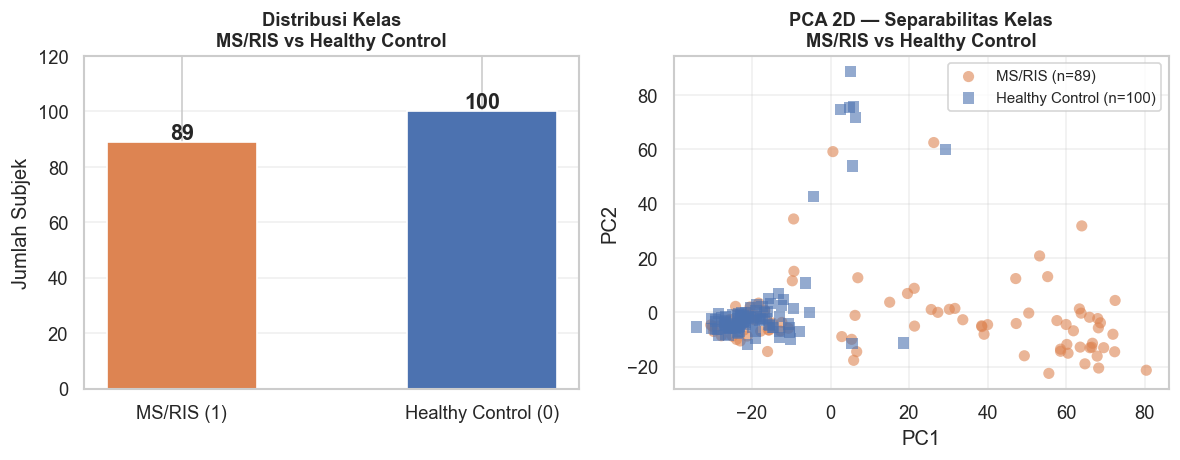

  Plot disimpan: 'ConfigdanOutputCNN189\distribusi_kelas_189.png'

  Section 6 — Ringkasan
  Task              : Binary Classification
  Label 1 (MS/RIS)  : 89 subjek (47.1%)
  Label 0 (HC)      : 100 subjek (52.9%)
  Total             : 189 subjek
  Imbalance Ratio   : 1.12:1
  Augmentasi        : Tidak diperlukan
  X_final shape     : (189, 121)
  y_final shape     : (189,)
  Variabel aktif: X_final, y_final
  Lanjut ke Cell 7 — Split 80/20 + Stratified K-Fold


In [10]:
# CELL 6 — LABELING & DISTRIBUSI KELAS
# Deskripsi: Sinkronisasi df_cnn_features dengan labels_series,
#            validasi distribusi kelas, keputusan augmentasi,
#            dan siapkan X_final + y_final untuk modeling.
#            Label: MS/RIS = 1 | Healthy Control = 0
# ============================================================

# ── Section 1: Sinkronisasi Index ────────────────────────────
print("=" * 60)
print("Section 1: Sinkronisasi df_cnn_features & labels_series")
print("=" * 60)

# Pastikan kedua index selaras sebelum membuat X dan y
common_idx = df_cnn_features.index.intersection(labels_series.index)

df_features_aligned = df_cnn_features.loc[common_idx]
labels_aligned      = labels_series.loc[common_idx]

print(f"  Index df_cnn_features  : {len(df_cnn_features)}")
print(f"  Index labels_series    : {len(labels_series)}")
print(f"  Index setelah intersect: {len(common_idx)}")

if len(common_idx) < len(df_cnn_features):
    missing = df_cnn_features.index.difference(labels_series.index)
    print(f"  ⚠ {len(missing)} subjek tanpa label: {missing.tolist()}")
else:
    print("  ✓ Sinkronisasi sempurna — semua subjek memiliki label")

# ── Section 2: Distribusi Kelas ───────────────────────────────
print("\nSection 2: Distribusi Kelas")
print("-" * 60)

n_ms  = sum(labels_aligned == 1)
n_hc  = sum(labels_aligned == 0)
n_tot = len(labels_aligned)

for lbl, name, cnt in [
    (1, 'MS/RIS',          n_ms),
    (0, 'Healthy Control', n_hc)
]:
    pct = cnt / n_tot * 100
    bar = '█' * int(pct / 2)
    print(f"  Label {lbl} ({name:<17}): {cnt:>3} ({pct:.1f}%) {bar}")

ir = max(n_ms, n_hc) / min(n_ms, n_hc)
print(f"\n  Total subjek    : {n_tot}")
print(f"  Imbalance Ratio : {ir:.2f}:1")

# ── Section 3: Keputusan Augmentasi ──────────────────────────
print("\nSection 3: Keputusan Augmentasi")
print("-" * 60)

IR_THRESHOLD = 1.5
print(f"  Imbalance Ratio  : {ir:.2f}:1")
print(f"  Threshold        : {IR_THRESHOLD}:1")

if ir > IR_THRESHOLD:
    print("  → IR > 1.5 : Augmentasi diperlukan")
else:
    print("  → IR ≤ 1.5 : Augmentasi TIDAK diperlukan")
    print("  Justifikasi akademik:")
    print(f"  Berdasarkan Chawla et al. (2002) dan He & Garcia (2009),")
    print(f"  oversampling direkomendasikan ketika IR > 1.5:1.")
    print(f"  Dengan IR = {ir:.2f}:1, distribusi dinilai cukup seimbang.")

# ── Section 4: Siapkan X_final & y_final ─────────────────────
print("\nSection 4: Siapkan X_final & y_final")
print("-" * 60)

X_final = df_features_aligned.values        # (189, 121) numpy array
y_final = labels_aligned.values.astype(int) # (189,) numpy array

print(f"  X_final shape : {X_final.shape}")
print(f"  y_final shape : {y_final.shape}")
print(f"  dtype X       : {X_final.dtype}")
print(f"  dtype y       : {y_final.dtype}")
print(f"  Nilai unik y  : {np.unique(y_final, return_counts=True)}")

# ── Section 5: Visualisasi Distribusi ────────────────────────
print("\nSection 5: Visualisasi Distribusi Kelas")
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart distribusi
colors = ['#DD8452', '#4C72B0']   # oranye=MS, biru=HC
bars   = axes[0].bar(
    ['MS/RIS (1)', 'Healthy Control (0)'],
    [n_ms, n_hc],
    color=colors, edgecolor='white', width=0.5
)
axes[0].set_title('Distribusi Kelas\nMS/RIS vs Healthy Control',
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel('Jumlah Subjek')
axes[0].set_ylim([0, max(n_ms, n_hc) * 1.2])
for bar, cnt in zip(bars, [n_ms, n_hc]):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 1,
                str(cnt), ha='center',
                fontsize=13, fontweight='bold')
axes[0].grid(True, axis='y', alpha=0.3)

# PCA 2D scatter — visualisasi separabilitas kelas
pca_vis = PCA(n_components=2, random_state=42)
X_2d    = pca_vis.fit_transform(X_final)

for lbl, name, color, marker in [
    (1, 'MS/RIS',          '#DD8452', 'o'),
    (0, 'Healthy Control', '#4C72B0', 's')
]:
    mask = y_final == lbl
    axes[1].scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=color, label=f'{name} (n={mask.sum()})',
                   alpha=0.6, s=45, marker=marker, edgecolors='none')

axes[1].set_title('PCA 2D — Separabilitas Kelas\nMS/RIS vs Healthy Control',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN189\distribusi_kelas_189.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Plot disimpan: 'ConfigdanOutputCNN189\distribusi_kelas_189.png'")

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan")
print("=" * 60)
print(f"  Task              : Binary Classification")
print(f"  Label 1 (MS/RIS)  : {n_ms} subjek ({n_ms/n_tot*100:.1f}%)")
print(f"  Label 0 (HC)      : {n_hc} subjek ({n_hc/n_tot*100:.1f}%)")
print(f"  Total             : {n_tot} subjek")
print(f"  Imbalance Ratio   : {ir:.2f}:1")
print(f"  Augmentasi        : {'Diperlukan' if ir > IR_THRESHOLD else 'Tidak diperlukan'}")
print(f"  X_final shape     : {X_final.shape}")
print(f"  y_final shape     : {y_final.shape}")
print("=" * 60)
print("  Variabel aktif: X_final, y_final")
print("  Lanjut ke Cell 7 — Split 80/20 + Stratified K-Fold")

In [20]:
# CELL 7 — SPLIT DATA 80/20 + STRATIFIED K-FOLD
# Deskripsi: Split X_final/y_final menjadi train (80%)
#            dan test (20%) secara stratified.
#            K-Fold hanya diterapkan pada train set.
#            Test set TIDAK disentuh selama training.
# ============================================================

# ── KONFIGURASI SPLIT ─────────────────────────────────────────
# ┌──────────────────────────────────────────────────────────┐
# │ TEST_SIZE = 0.20 → 80% train | 20% test  (default)      │
# │ TEST_SIZE = 0.25 → 75% train | 25% test                 │
# │ TEST_SIZE = 0.30 → 70% train | 30% test                 │
# └──────────────────────────────────────────────────────────┘
TEST_SIZE    = 0.30
N_SPLITS     = 5
RANDOM_STATE = 42

# ── Section 1: Train/Test Split ──────────────────────────────
print("=" * 60)
print("Section 1: Train/Test Split (Stratified)")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final,
    test_size    = TEST_SIZE,
    stratify     = y_final,
    random_state = RANDOM_STATE
)

print(f"  Rasio split      : {int((1-TEST_SIZE)*100)}% train | {int(TEST_SIZE*100)}% test")
print(f"  Total subjek     : {len(X_final)}")
print(f"\n  {'Set':<8} {'Total':>7} {'MS/RIS':>8} {'HC':>8} {'IR':>8}")
print(f"  {'-'*44}")

for name, X_s, y_s in [('Train', X_train, y_train),
                          ('Test',  X_test,  y_test)]:
    n_ms_s  = sum(y_s == 1)
    n_hc_s  = sum(y_s == 0)
    ir_s    = max(n_ms_s, n_hc_s) / min(n_ms_s, n_hc_s)
    print(f"  {name:<8} {len(X_s):>7} {n_ms_s:>8} {n_hc_s:>8} {ir_s:>7.2f}:1")

print(f"\n  Proporsi kelas di Train:")
print(f"    MS/RIS : {sum(y_train==1)/len(y_train)*100:.1f}%")
print(f"    HC     : {sum(y_train==0)/len(y_train)*100:.1f}%")
print(f"  Proporsi kelas di Test:")
print(f"    MS/RIS : {sum(y_test==1)/len(y_test)*100:.1f}%")
print(f"    HC     : {sum(y_test==0)/len(y_test)*100:.1f}%")

# ── Section 2: Inisialisasi Stratified K-Fold ────────────────
print("\nSection 2: Inisialisasi Stratified K-Fold")
print("-" * 60)

kfold = StratifiedKFold(
    n_splits     = N_SPLITS,
    shuffle      = True,
    random_state = RANDOM_STATE
)

print(f"  Metode         : Stratified K-Fold")
print(f"  n_splits (k)   : {N_SPLITS}")
print(f"  Diterapkan pada: Train set ({len(X_train)} subjek)")
print(f"  Estimasi train : ~{int(len(X_train)*(N_SPLITS-1)/N_SPLITS)} subjek/fold")
print(f"  Estimasi val   : ~{int(len(X_train)/N_SPLITS)} subjek/fold")

# ── Section 3: Verifikasi Distribusi per Fold ────────────────
print("\nSection 3: Verifikasi Distribusi Kelas per Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Train':>6} {'Val':>5} │ "
      f"{'Tr-MS':>6} {'Tr-HC':>6} │ "
      f"{'Vl-MS':>6} {'Vl-HC':>6}")
print(f"  {'-'*52}")

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):
    y_tr = y_train[tr_idx]
    y_vl = y_train[vl_idx]
    print(f"  Fold {fold:<2}  {len(tr_idx):>5}  {len(vl_idx):>4} │ "
          f"  {sum(y_tr==1):>3} ({sum(y_tr==1)/len(y_tr)*100:.0f}%)"
          f"  {sum(y_tr==0):>3} ({sum(y_tr==0)/len(y_tr)*100:.0f}%) │ "
          f"  {sum(y_vl==1):>3} ({sum(y_vl==1)/len(y_vl)*100:.0f}%)"
          f"  {sum(y_vl==0):>3} ({sum(y_vl==0)/len(y_vl)*100:.0f}%)")

# ── Section 4: Ringkasan Konfigurasi ─────────────────────────
print("\n" + "=" * 60)
print("  Section 4 — Ringkasan Konfigurasi")
print("=" * 60)
print(f"  Split          : {int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)} stratified")
print(f"  Train set      : {len(X_train)} subjek → K-Fold training")
print(f"  Test set       : {len(X_test)} subjek → evaluasi akhir (hold-out)")
print(f"  K-Fold         : Stratified, k={N_SPLITS}, seed={RANDOM_STATE}")
print(f"  Normalisasi    : StandardScaler fit per fold (anti data leakage)")
print(f"\n  Alur modeling Cell 8–10:")
print("    K-Fold (X_train) → metrik validasi per fold")
print("    Retrain seluruh X_train → evaluasi final di X_test")
print("=" * 60)
print("  Variabel aktif: X_train, X_test, y_train, y_test, kfold")
print("  Lanjut ke Cell 8 — Gradient Boosting + K-Fold")

Section 1: Train/Test Split (Stratified)
  Rasio split      : 70% train | 30% test
  Total subjek     : 189

  Set        Total   MS/RIS       HC       IR
  --------------------------------------------
  Train        132       62       70    1.13:1
  Test          57       27       30    1.11:1

  Proporsi kelas di Train:
    MS/RIS : 47.0%
    HC     : 53.0%
  Proporsi kelas di Test:
    MS/RIS : 47.4%
    HC     : 52.6%

Section 2: Inisialisasi Stratified K-Fold
------------------------------------------------------------
  Metode         : Stratified K-Fold
  n_splits (k)   : 5
  Diterapkan pada: Train set (132 subjek)
  Estimasi train : ~105 subjek/fold
  Estimasi val   : ~26 subjek/fold

Section 3: Verifikasi Distribusi Kelas per Fold
------------------------------------------------------------
  Fold    Train   Val │  Tr-MS  Tr-HC │  Vl-MS  Vl-HC
  ----------------------------------------------------
  Fold 1     105    27 │    49 (47%)   56 (53%) │    13 (48%)   14 (52%)
  Fold 

Section 1: Gradient Boosting — Konfigurasi Model
  Algoritma     : Gradient Boosting Classifier
  Dataset        : X_train (132, 121)
  Task           : MS/RIS (1) vs HC (0)
  n_estimators     : 100
  learning_rate    : 0.1
  max_depth        : 3
  subsample        : 0.8
  random_state     : 42

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.7037 1.0000 0.3846 0.5556 0.8956
  Fold 2  0.8889 0.8571 0.9231 0.8889 0.9670
  Fold 3  0.6538 0.6667 0.5000 0.5714 0.7083
  Fold 4  0.8846 1.0000 0.7500 0.8571 0.8452
  Fold 5  0.8077 0.7692 0.8333 0.8000 0.9048

Section 3: Rata-rata Metrik K-Fold (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.7877 ± 0.1061
  Precision  : 0.8586 ± 0.1456
  Recall     : 0.6782 ± 0.2276
  F1-Score   : 0.7346 ± 0.1595
  AUC-ROC    : 0.8642 ± 0.0973

Section 4: Evaluasi Final pa

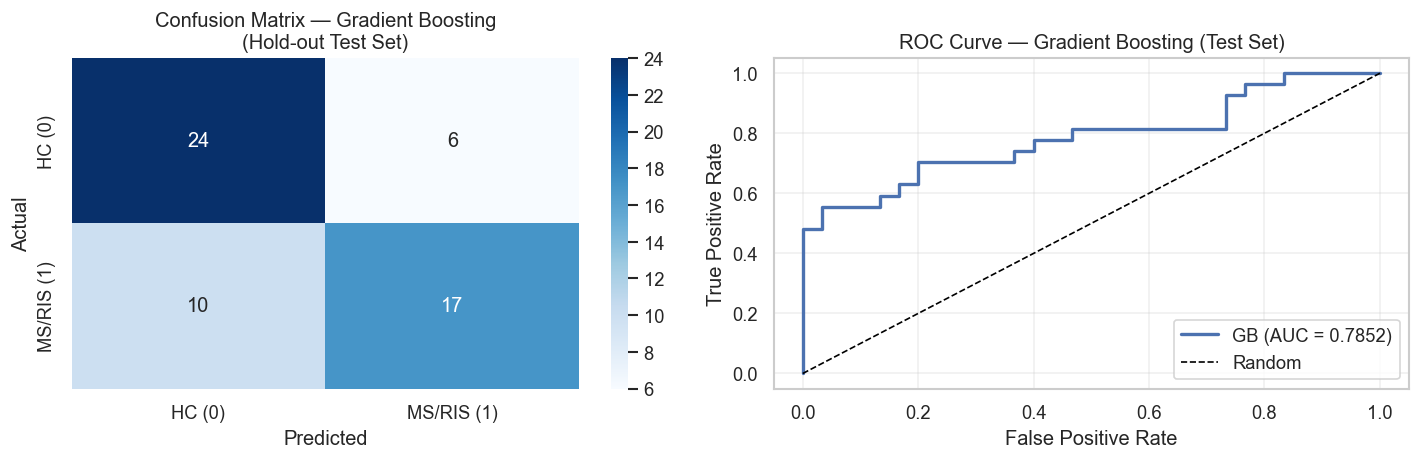


  Section 6 — Ringkasan Gradient Boosting
  [K-Fold Val]  Accuracy : 0.7877 ± 0.1061
  [K-Fold Val]  F1-Score : 0.7346 ± 0.1595
  [K-Fold Val]  AUC-ROC  : 0.8642 ± 0.0973
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.7193
  [Test Set]    F1-Score : 0.6800
  [Test Set]    AUC-ROC  : 0.7852
  [Test Set]    FN kritis: 10 dari 27 MS/RIS
  Variabel aktif: results_gb, final_model_gb, cm_gb
  Lanjut ke Cell 9 — XGBoost + K-Fold


In [21]:
# CELL 8 — GRADIENT BOOSTING + K-FOLD
# Deskripsi: Training GB pada X_train (151 subjek)
#            dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (38 subjek hold-out).
#            Task: Binary — MS/RIS (1) vs HC (0)
# ============================================================

GB_PARAMS = {
    'n_estimators'  : 100,
    'learning_rate' : 0.1,
    'max_depth'     : 3,
    'subsample'     : 0.8,
    'random_state'  : 42
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: Gradient Boosting — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Gradient Boosting Classifier")
print(f"  Dataset        : X_train {X_train.shape}")
print(f"  Task           : MS/RIS (1) vs HC (0)")
for k, v in GB_PARAMS.items():
    print(f"  {k:<17}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

fold_metrics_gb  = []
all_y_true_gb    = []
all_y_pred_gb    = []
all_y_prob_gb    = []
best_model_gb    = None
best_f1_gb       = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model = GradientBoostingClassifier(**GB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]
    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_gb.append({
        'fold': fold, 'acc': acc,  'prec': prec,
        'rec': rec,   'f1': f1,   'auc': auc_score
    })
    all_y_true_gb.extend(y_vl)
    all_y_pred_gb.extend(y_pred)
    all_y_prob_gb.extend(y_prob)

    if f1 > best_f1_gb:
        best_f1_gb    = f1
        best_model_gb = model
        best_scaler_gb = scaler

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_gb   = pd.DataFrame(fold_metrics_gb)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_gb = {}
for m in metrics_list:
    mean = df_fold_gb[m].mean()
    std  = df_fold_gb[m].std()
    results_gb[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test ────────────────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

scaler_final_gb  = StandardScaler()
X_train_sc       = scaler_final_gb.fit_transform(X_train)
X_test_sc        = scaler_final_gb.transform(X_test)

final_model_gb   = GradientBoostingClassifier(**GB_PARAMS)
final_model_gb.fit(X_train_sc, y_train)

y_pred_test_gb   = final_model_gb.predict(X_test_sc)
y_prob_test_gb   = final_model_gb.predict_proba(X_test_sc)[:, 1]

test_acc_gb  = accuracy_score(y_test, y_pred_test_gb)
test_prec_gb = precision_score(y_test, y_pred_test_gb, zero_division=0)
test_rec_gb  = recall_score(y_test, y_pred_test_gb, zero_division=0)
test_f1_gb   = f1_score(y_test, y_pred_test_gb, zero_division=0)
test_auc_gb  = roc_auc_score(y_test, y_prob_test_gb)

print(f"  Accuracy  : {test_acc_gb:.4f}")
print(f"  Precision : {test_prec_gb:.4f}")
print(f"  Recall    : {test_rec_gb:.4f}")
print(f"  F1-Score  : {test_f1_gb:.4f}")
print(f"  AUC-ROC   : {test_auc_gb:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_gb = confusion_matrix(y_test, y_pred_test_gb)
print(f"  TN={cm_gb[0,0]}  FP={cm_gb[0,1]}")
print(f"  FN={cm_gb[1,0]}  TP={cm_gb[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS/RIS terdeteksi benar) : {cm_gb[1,1]}")
print(f"  TN (HC terdeteksi benar)     : {cm_gb[0,0]}")
print(f"  FP (HC salah prediksi MS)    : {cm_gb[0,1]}")
print(f"  FN (MS terlewat — kritis)    : {cm_gb[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_gb,
    target_names=['HC (0)', 'MS/RIS (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['HC (0)', 'MS/RIS (1)'],
            yticklabels=['HC (0)', 'MS/RIS (1)'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — Gradient Boosting\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_gb, tpr_gb, _ = roc_curve(y_test, y_prob_test_gb)
roc_val_gb        = auc(fpr_gb, tpr_gb)
axes[1].plot(fpr_gb, tpr_gb, color='#4C72B0', lw=2,
             label=f'GB (AUC = {roc_val_gb:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Gradient Boosting (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN189\gb_evaluation_189.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan Gradient Boosting")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_gb['acc']['mean']:.4f} ± {results_gb['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_gb['f1']['mean']:.4f} ± {results_gb['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_gb['auc']['mean']:.4f} ± {results_gb['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_gb:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_gb:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_gb:.4f}")
print(f"  [Test Set]    FN kritis: {cm_gb[1,0]} dari {sum(y_test==1)} MS/RIS")
print("=" * 60)
print("  Variabel aktif: results_gb, final_model_gb, cm_gb")
print("  Lanjut ke Cell 9 — XGBoost + K-Fold")

Section 1: XGBoost — Konfigurasi Model
  Algoritma     : XGBoost Classifier
  Dataset        : X_train (132, 121)
  Task           : MS/RIS (1) vs HC (0)
  n_estimators          : 100
  learning_rate         : 0.1
  max_depth             : 3
  subsample             : 0.8
  colsample_bytree      : 0.8
  use_label_encoder     : False
  eval_metric           : logloss
  random_state          : 42
  verbosity             : 0

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC
  --------------------------------------
  Fold 1  0.7037 0.8571 0.4615 0.6000 0.8462
  Fold 2  0.8889 0.8571 0.9231 0.8889 0.9615
  Fold 3  0.6154 0.6250 0.4167 0.5000 0.6548
  Fold 4  0.8462 0.9000 0.7500 0.8182 0.8571
  Fold 5  0.8077 0.7692 0.8333 0.8000 0.8095

Section 3: Rata-rata Metrik K-Fold (Mean ± Std)
------------------------------------------------------------
  Accuracy   : 0.7724 ± 0.1114
  Precision  : 0.8017 ± 

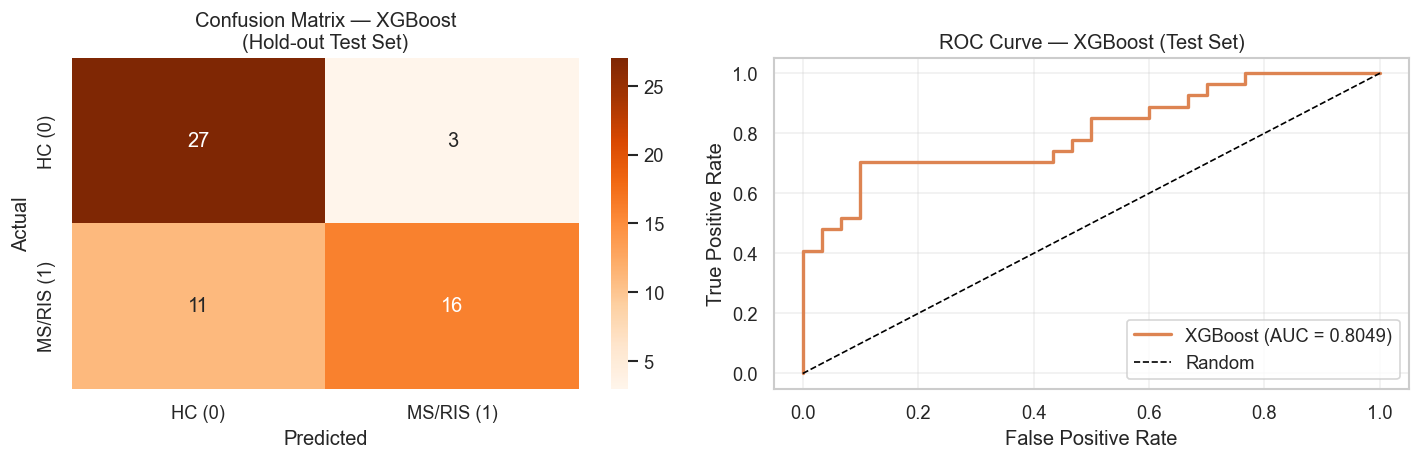


  Section 6 — Ringkasan XGBoost
  [K-Fold Val]  Accuracy : 0.7724 ± 0.1114
  [K-Fold Val]  F1-Score : 0.7214 ± 0.1638
  [K-Fold Val]  AUC-ROC  : 0.8258 ± 0.1111
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.7544
  [Test Set]    F1-Score : 0.6957
  [Test Set]    AUC-ROC  : 0.8049
  [Test Set]    FN kritis: 11 dari 27 MS/RIS
  Variabel aktif: results_xgb, final_model_xgb, cm_xgb
  Lanjut ke Cell 10 — MLP + K-Fold


In [22]:
# CELL 9 — XGBOOST + K-FOLD
# Deskripsi: Training XGBoost pada X_train (151 subjek)
#            dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (38 subjek hold-out).
#            Task: Binary — MS/RIS (1) vs HC (0)
# ============================================================

XGB_PARAMS = {
    'n_estimators'    : 100,
    'learning_rate'   : 0.1,
    'max_depth'       : 3,
    'subsample'       : 0.8,
    'colsample_bytree': 0.8,
    'use_label_encoder': False,
    'eval_metric'     : 'logloss',
    'random_state'    : 42,
    'verbosity'       : 0
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: XGBoost — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : XGBoost Classifier")
print(f"  Dataset        : X_train {X_train.shape}")
print(f"  Task           : MS/RIS (1) vs HC (0)")
for k, v in XGB_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6}")
print(f"  {'-'*38}")

fold_metrics_xgb  = []
all_y_true_xgb    = []
all_y_pred_xgb    = []
all_y_prob_xgb    = []
best_model_xgb    = None
best_f1_xgb       = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model = XGBClassifier(**XGB_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]
    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_xgb.append({
        'fold': fold, 'acc': acc,  'prec': prec,
        'rec': rec,   'f1': f1,   'auc': auc_score
    })
    all_y_true_xgb.extend(y_vl)
    all_y_pred_xgb.extend(y_pred)
    all_y_prob_xgb.extend(y_prob)

    if f1 > best_f1_xgb:
        best_f1_xgb    = f1
        best_model_xgb = model
        best_scaler_xgb = scaler

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} {f1:.4f} {auc_score:.4f}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_xgb  = pd.DataFrame(fold_metrics_xgb)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_xgb = {}
for m in metrics_list:
    mean = df_fold_xgb[m].mean()
    std  = df_fold_xgb[m].std()
    results_xgb[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test ────────────────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

scaler_final_xgb = StandardScaler()
X_train_sc       = scaler_final_xgb.fit_transform(X_train)
X_test_sc        = scaler_final_xgb.transform(X_test)

final_model_xgb  = XGBClassifier(**XGB_PARAMS)
final_model_xgb.fit(X_train_sc, y_train)

y_pred_test_xgb  = final_model_xgb.predict(X_test_sc)
y_prob_test_xgb  = final_model_xgb.predict_proba(X_test_sc)[:, 1]

test_acc_xgb  = accuracy_score(y_test, y_pred_test_xgb)
test_prec_xgb = precision_score(y_test, y_pred_test_xgb, zero_division=0)
test_rec_xgb  = recall_score(y_test, y_pred_test_xgb, zero_division=0)
test_f1_xgb   = f1_score(y_test, y_pred_test_xgb, zero_division=0)
test_auc_xgb  = roc_auc_score(y_test, y_prob_test_xgb)

print(f"  Accuracy  : {test_acc_xgb:.4f}")
print(f"  Precision : {test_prec_xgb:.4f}")
print(f"  Recall    : {test_rec_xgb:.4f}")
print(f"  F1-Score  : {test_f1_xgb:.4f}")
print(f"  AUC-ROC   : {test_auc_xgb:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_xgb = confusion_matrix(y_test, y_pred_test_xgb)
print(f"  TN={cm_xgb[0,0]}  FP={cm_xgb[0,1]}")
print(f"  FN={cm_xgb[1,0]}  TP={cm_xgb[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS/RIS terdeteksi benar) : {cm_xgb[1,1]}")
print(f"  TN (HC terdeteksi benar)     : {cm_xgb[0,0]}")
print(f"  FP (HC salah prediksi MS)    : {cm_xgb[0,1]}")
print(f"  FN (MS terlewat — kritis)    : {cm_xgb[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_xgb,
    target_names=['HC (0)', 'MS/RIS (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['HC (0)', 'MS/RIS (1)'],
            yticklabels=['HC (0)', 'MS/RIS (1)'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — XGBoost\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_test_xgb)
roc_val_xgb          = auc(fpr_xgb, tpr_xgb)
axes[1].plot(fpr_xgb, tpr_xgb, color='#DD8452', lw=2,
             label=f'XGBoost (AUC = {roc_val_xgb:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — XGBoost (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN189\Xgb_evaluation_189.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan XGBoost")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_xgb['acc']['mean']:.4f} ± {results_xgb['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_xgb['f1']['mean']:.4f} ± {results_xgb['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_xgb['auc']['mean']:.4f} ± {results_xgb['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_xgb:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_xgb:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_xgb:.4f}")
print(f"  [Test Set]    FN kritis: {cm_xgb[1,0]} dari {sum(y_test==1)} MS/RIS")
print("=" * 60)
print("  Variabel aktif: results_xgb, final_model_xgb, cm_xgb")
print("  Lanjut ke Cell 10 — MLP + K-Fold")

Section 1: MLP — Konfigurasi Model
  Algoritma     : Multi-Layer Perceptron
  Arsitektur     : Input(121) → Dense(64) → Dense(32) → Output(1)
  Dataset        : X_train (132, 121)
  Task           : MS/RIS (1) vs HC (0)
  hidden_layer_sizes    : (64, 32)
  activation            : relu
  solver                : adam
  alpha                 : 0.01
  learning_rate         : adaptive
  learning_rate_init    : 0.001
  max_iter              : 500
  early_stopping        : True
  validation_fraction   : 0.1
  n_iter_no_change      : 20
  random_state          : 42

Section 2: Training Stratified K-Fold
------------------------------------------------------------
  Fold      Acc   Prec    Rec     F1    AUC   Iter
  ---------------------------------------------
  Fold 1  0.6667 0.6250 0.7692 0.6897 0.6813    22
  Fold 2  0.6667 0.6667 0.6154 0.6400 0.6758    22
  Fold 3  0.6154 0.6250 0.4167 0.5000 0.6488    47
  Fold 4  0.5769 0.5455 0.5000 0.5217 0.5774    35
  Fold 5  0.4231 0.3846 0.4167 0.

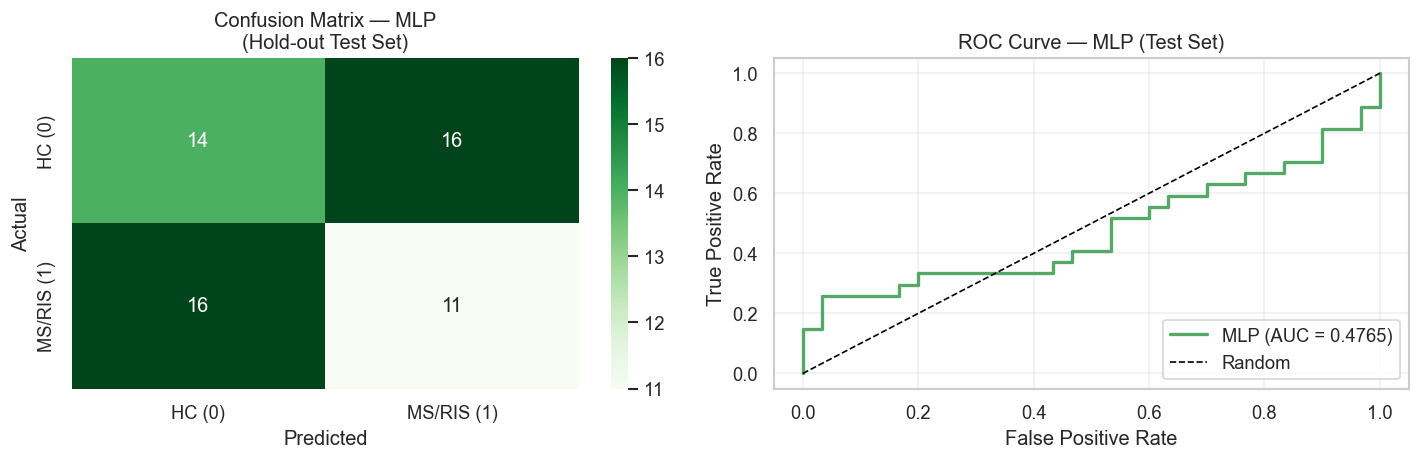


  Section 6 — Ringkasan MLP
  [K-Fold Val]  Accuracy : 0.5897 ± 0.1005
  [K-Fold Val]  F1-Score : 0.5503 ± 0.1155
  [K-Fold Val]  AUC-ROC  : 0.6083 ± 0.0935
  ────────────────────────────────────────
  [Test Set]    Accuracy : 0.4386
  [Test Set]    F1-Score : 0.4074
  [Test Set]    AUC-ROC  : 0.4765
  [Test Set]    FN kritis: 16 dari 27 MS/RIS
  Arsitektur    : Input(121) → Dense(64) → Dense(32) → Output(1)
  Variabel aktif: results_mlp, final_model_mlp, cm_mlp
  Lanjut ke Cell 11 — Evaluasi Komparatif


In [23]:
# CELL 10 — MLP + K-FOLD
# Deskripsi: Training MLP pada X_train (151 subjek)
#            dengan Stratified K-Fold (k=5).
#            Evaluasi akhir pada X_test (38 subjek hold-out).
#            Task: Binary — MS/RIS (1) vs HC (0)
# ============================================================

MLP_PARAMS = {
    'hidden_layer_sizes' : (64, 32),
    'activation'         : 'relu',
    'solver'             : 'adam',
    'alpha'              : 0.01,
    'learning_rate'      : 'adaptive',
    'learning_rate_init' : 0.001,
    'max_iter'           : 500,
    'early_stopping'     : True,
    'validation_fraction': 0.1,
    'n_iter_no_change'   : 20,
    'random_state'       : 42
}

# ── Section 1: Konfigurasi ────────────────────────────────────
print("=" * 60)
print("Section 1: MLP — Konfigurasi Model")
print("=" * 60)
print("  Algoritma     : Multi-Layer Perceptron")
print(f"  Arsitektur     : Input(121) → Dense(64) → Dense(32) → Output(1)")
print(f"  Dataset        : X_train {X_train.shape}")
print(f"  Task           : MS/RIS (1) vs HC (0)")
for k, v in MLP_PARAMS.items():
    print(f"  {k:<22}: {v}")

# ── Section 2: Training K-Fold ────────────────────────────────
print("\nSection 2: Training Stratified K-Fold")
print("-" * 60)
print(f"  {'Fold':<6} {'Acc':>6} {'Prec':>6} {'Rec':>6} {'F1':>6} {'AUC':>6} {'Iter':>6}")
print(f"  {'-'*45}")

fold_metrics_mlp  = []
all_y_true_mlp    = []
all_y_pred_mlp    = []
all_y_prob_mlp    = []
best_model_mlp    = None
best_f1_mlp       = -1

for fold, (tr_idx, vl_idx) in enumerate(
        kfold.split(X_train, y_train), 1):

    X_tr, X_vl = X_train[tr_idx], X_train[vl_idx]
    y_tr, y_vl = y_train[tr_idx], y_train[vl_idx]

    scaler  = StandardScaler()
    X_tr_sc = scaler.fit_transform(X_tr)
    X_vl_sc = scaler.transform(X_vl)

    model  = MLPClassifier(**MLP_PARAMS)
    model.fit(X_tr_sc, y_tr)

    y_pred    = model.predict(X_vl_sc)
    y_prob    = model.predict_proba(X_vl_sc)[:, 1]
    n_iter    = model.n_iter_

    acc       = accuracy_score(y_vl, y_pred)
    prec      = precision_score(y_vl, y_pred, zero_division=0)
    rec       = recall_score(y_vl, y_pred, zero_division=0)
    f1        = f1_score(y_vl, y_pred, zero_division=0)
    auc_score = roc_auc_score(y_vl, y_prob)

    fold_metrics_mlp.append({
        'fold': fold, 'acc': acc,  'prec': prec,
        'rec': rec,   'f1': f1,   'auc': auc_score
    })
    all_y_true_mlp.extend(y_vl)
    all_y_pred_mlp.extend(y_pred)
    all_y_prob_mlp.extend(y_prob)

    if f1 > best_f1_mlp:
        best_f1_mlp    = f1
        best_model_mlp = model
        best_scaler_mlp = scaler

    print(f"  Fold {fold}  {acc:.4f} {prec:.4f} {rec:.4f} "
          f"{f1:.4f} {auc_score:.4f} {n_iter:>5}")

# ── Section 3: Rata-rata Metrik K-Fold ───────────────────────
print(f"\nSection 3: Rata-rata Metrik K-Fold (Mean ± Std)")
print("-" * 60)

df_fold_mlp  = pd.DataFrame(fold_metrics_mlp)
metrics_list = ['acc', 'prec', 'rec', 'f1', 'auc']
label_map    = {
    'acc':'Accuracy', 'prec':'Precision', 'rec':'Recall',
    'f1':'F1-Score',  'auc':'AUC-ROC'
}

results_mlp = {}
for m in metrics_list:
    mean = df_fold_mlp[m].mean()
    std  = df_fold_mlp[m].std()
    results_mlp[m] = {'mean': mean, 'std': std}
    print(f"  {label_map[m]:<11}: {mean:.4f} ± {std:.4f}")

# ── Section 4: Evaluasi Final pada X_test ────────────────────
print(f"\nSection 4: Evaluasi Final pada X_test (Hold-out 20%)")
print("-" * 60)

scaler_final_mlp = StandardScaler()
X_train_sc       = scaler_final_mlp.fit_transform(X_train)
X_test_sc        = scaler_final_mlp.transform(X_test)

final_model_mlp  = MLPClassifier(**MLP_PARAMS)
final_model_mlp.fit(X_train_sc, y_train)

y_pred_test_mlp  = final_model_mlp.predict(X_test_sc)
y_prob_test_mlp  = final_model_mlp.predict_proba(X_test_sc)[:, 1]

test_acc_mlp  = accuracy_score(y_test, y_pred_test_mlp)
test_prec_mlp = precision_score(y_test, y_pred_test_mlp, zero_division=0)
test_rec_mlp  = recall_score(y_test, y_pred_test_mlp, zero_division=0)
test_f1_mlp   = f1_score(y_test, y_pred_test_mlp, zero_division=0)
test_auc_mlp  = roc_auc_score(y_test, y_prob_test_mlp)

print(f"  Accuracy  : {test_acc_mlp:.4f}")
print(f"  Precision : {test_prec_mlp:.4f}")
print(f"  Recall    : {test_rec_mlp:.4f}")
print(f"  F1-Score  : {test_f1_mlp:.4f}")
print(f"  AUC-ROC   : {test_auc_mlp:.4f}")

# ── Section 5: Confusion Matrix + Classification Report ──────
print(f"\nSection 5: Confusion Matrix + Classification Report")
print("-" * 60)

cm_mlp = confusion_matrix(y_test, y_pred_test_mlp)
print(f"  TN={cm_mlp[0,0]}  FP={cm_mlp[0,1]}")
print(f"  FN={cm_mlp[1,0]}  TP={cm_mlp[1,1]}")
print(f"\n  Interpretasi:")
print(f"  TP (MS/RIS terdeteksi benar) : {cm_mlp[1,1]}")
print(f"  TN (HC terdeteksi benar)     : {cm_mlp[0,0]}")
print(f"  FP (HC salah prediksi MS)    : {cm_mlp[0,1]}")
print(f"  FN (MS terlewat — kritis)    : {cm_mlp[1,0]}")

print(f"\n  Classification Report (X_test):")
print(classification_report(
    y_test, y_pred_test_mlp,
    target_names=['HC (0)', 'MS/RIS (1)'],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Greens',
            xticklabels=['HC (0)', 'MS/RIS (1)'],
            yticklabels=['HC (0)', 'MS/RIS (1)'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — MLP\n(Hold-out Test Set)')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_prob_test_mlp)
roc_val_mlp          = auc(fpr_mlp, tpr_mlp)
axes[1].plot(fpr_mlp, tpr_mlp, color='#55A868', lw=2,
             label=f'MLP (AUC = {roc_val_mlp:.4f})')
axes[1].plot([0,1], [0,1], 'k--', lw=1, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — MLP (Test Set)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ConfigdanOutputCNN189\mlp_evaluation_189.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Section 6: Ringkasan ──────────────────────────────────────
print("\n" + "=" * 60)
print("  Section 6 — Ringkasan MLP")
print("=" * 60)
print(f"  [K-Fold Val]  Accuracy : {results_mlp['acc']['mean']:.4f} ± {results_mlp['acc']['std']:.4f}")
print(f"  [K-Fold Val]  F1-Score : {results_mlp['f1']['mean']:.4f} ± {results_mlp['f1']['std']:.4f}")
print(f"  [K-Fold Val]  AUC-ROC  : {results_mlp['auc']['mean']:.4f} ± {results_mlp['auc']['std']:.4f}")
print(f"  {'─'*40}")
print(f"  [Test Set]    Accuracy : {test_acc_mlp:.4f}")
print(f"  [Test Set]    F1-Score : {test_f1_mlp:.4f}")
print(f"  [Test Set]    AUC-ROC  : {test_auc_mlp:.4f}")
print(f"  [Test Set]    FN kritis: {cm_mlp[1,0]} dari {sum(y_test==1)} MS/RIS")
print(f"  Arsitektur    : Input(121) → Dense(64) → Dense(32) → Output(1)")
print("=" * 60)
print("  Variabel aktif: results_mlp, final_model_mlp, cm_mlp")
print("  Lanjut ke Cell 11 — Evaluasi Komparatif")